(344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


(342, 7)
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str
<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str


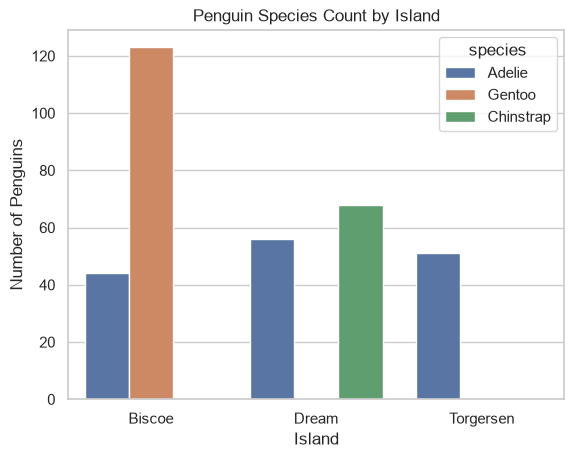

      island    species  count
0     Biscoe     Adelie     44
1     Biscoe     Gentoo    123
2      Dream     Adelie     56
3      Dream  Chinstrap     68
4  Torgersen     Adelie     51
island
Biscoe       167
Dream        124
Torgersen     51
dtype: int64
species    Adelie  Chinstrap  Gentoo
island                              
Biscoe       26.3        0.0    73.7
Dream        45.2       54.8     0.0
Torgersen   100.0        0.0     0.0
sex
Female    42.096970
Male      45.854762
Name: bill_length_mm, dtype: float64


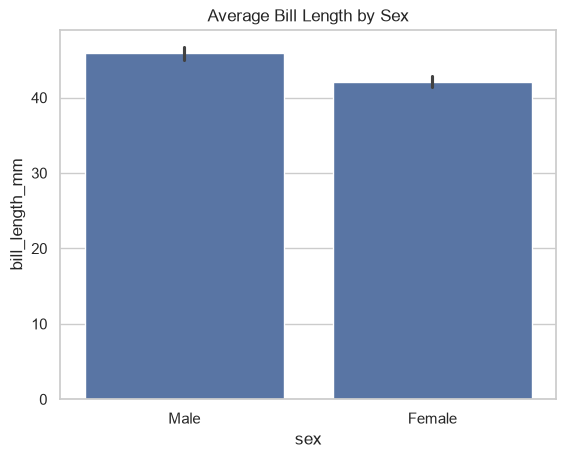

0.8712017673060112


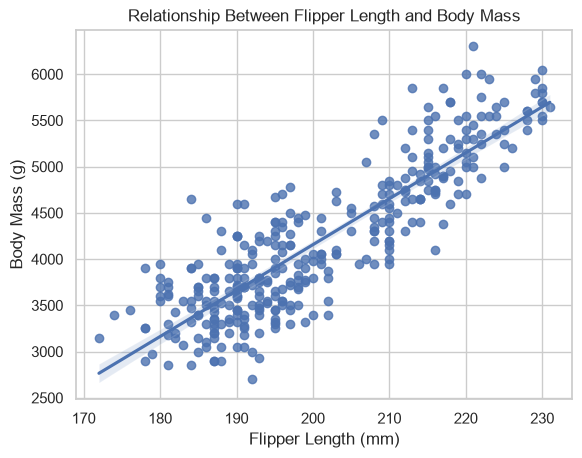

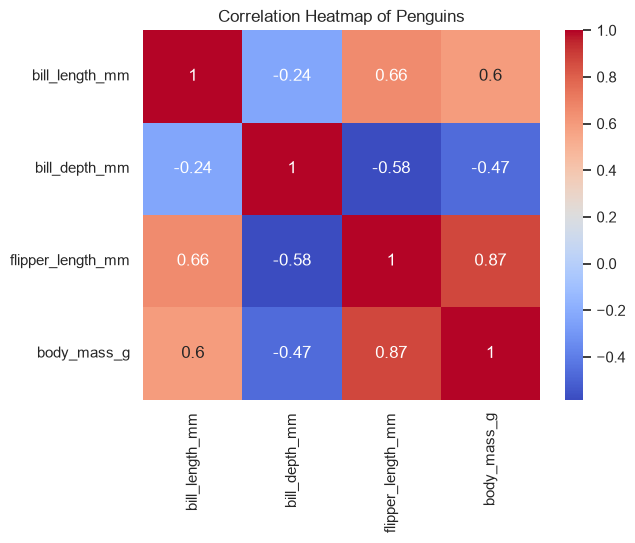

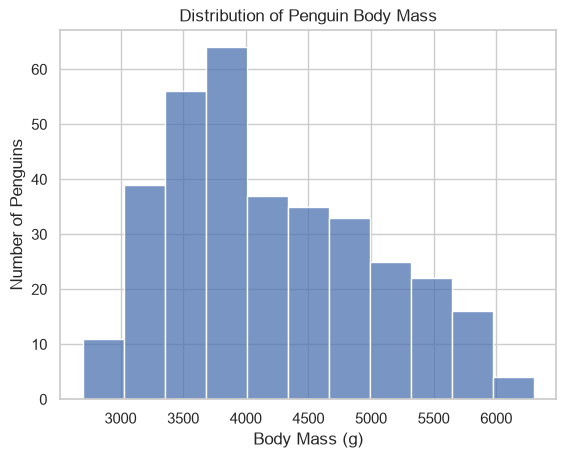

body_mass_g
(2696.4, 3060.0]    15
(3060.0, 3420.0]    43
(3420.0, 3780.0]    71
(3780.0, 4140.0]    53
(4140.0, 4500.0]    45
(4500.0, 4860.0]    38
(4860.0, 5220.0]    28
(5220.0, 5580.0]    27
(5580.0, 5940.0]    16
(5940.0, 6300.0]     6
Name: count, dtype: int64


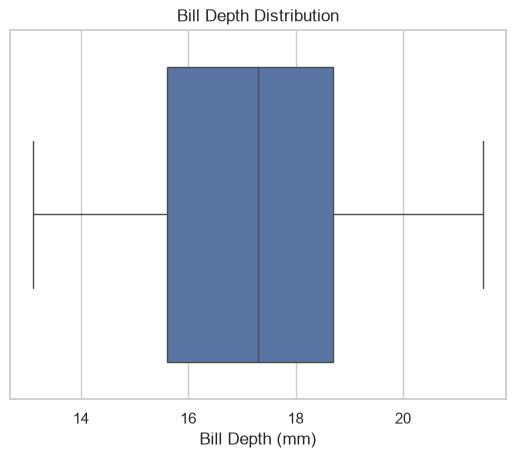

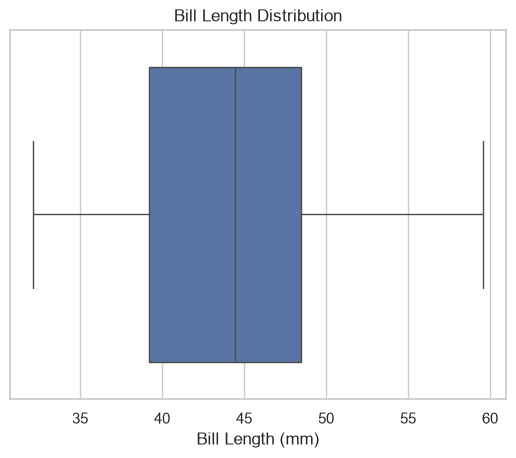

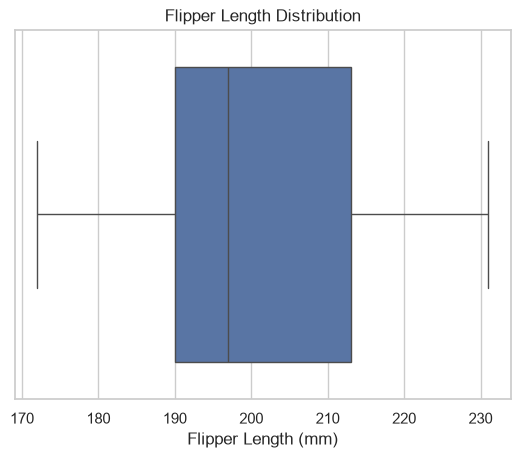

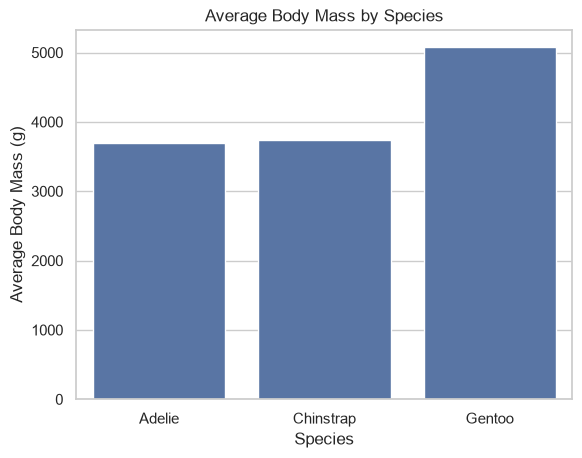

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display


sns.set_theme(style="whitegrid")


try:
    df = pd.read_csv("penguins.csv")


except FileNotFoundError:
    sns.load_dataset("penguins").to_csv("penguins.csv", index=False)
    df = pd.read_csv("penguins.csv")


print(df.shape)


df.info()


print(df.describe().round(1))


print(df.isna().sum())


display(df[df.isna().any(axis=1)])


display(df[df.isna().sum(axis=1) >= 5])

df = df.drop(index=[3, 339])


print(df.shape)

print(df.isna().sum())
display(df[df["sex"].isna()])

df.duplicated().sum()

print(df["species"].unique())
print(df["island"].unique())
print(df["sex"].unique())

counts = df.groupby(["island", "species"]).size().reset_index(name="count")

sns.barplot(data=counts, x="island", y="count", hue="species")
plt.title("Penguin Species Count by Island")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.savefig("species_by_island.png", bbox_inches="tight", dpi=300)
plt.show()
print(counts)
island_counts = df.groupby("island").size()
print(island_counts)
species_percentage = pd.crosstab(
    df["island"],
    df["species"],
    normalize="index"
) * 100

print(species_percentage.round(1))


print(df.groupby("sex")["bill_length_mm"].mean())
sns.barplot(data=df,x="sex",y="bill_length_mm")
plt.title("Average Bill Length by Sex")
plt.savefig("bill_length_by_sex.png", bbox_inches="tight", dpi=300)
plt.show()

print(df["flipper_length_mm"].corr(df["body_mass_g"]))

sns.regplot(data=df,x="flipper_length_mm",y="body_mass_g")
plt.title("Relationship Between Flipper Length and Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")

plt.savefig("flipper_vs_body_mass.png", bbox_inches="tight", dpi=300)
plt.show()

numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Penguins")
plt.savefig("correlation_heatmap.png")
plt.show()

sns.histplot(data=df,x="body_mass_g")
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Number of Penguins")

plt.savefig("body_mass_histogram.png", bbox_inches="tight", dpi=300)
plt.show()
df["body_mass_g"].describe()
print(pd.cut(df["body_mass_g"], bins=10).value_counts().sort_index())

sns.boxplot(data=df, x="bill_depth_mm")
plt.title("Bill Depth Distribution")
plt.xlabel("Bill Depth (mm)")
plt.savefig("bill_depth_boxplot.png", bbox_inches="tight", dpi=300)
plt.show()
sns.boxplot(data=df, x="bill_length_mm")
plt.title("Bill Length Distribution")
plt.xlabel("Bill Length (mm)")
plt.savefig("bill_length_boxplot.png", bbox_inches="tight", dpi=300)
plt.show()
sns.boxplot(data=df, x="flipper_length_mm")
plt.title("Flipper Length Distribution")
plt.xlabel("Flipper Length (mm)")
plt.savefig("flipper_length_boxplot.png", bbox_inches="tight", dpi=300)
plt.show()
avg = df.groupby("species")["body_mass_g"].mean().reset_index()
sns.barplot(data=avg, x="species", y="body_mass_g")
plt.title("Average Body Mass by Species")
plt.xlabel("Species")
plt.ylabel("Average Body Mass (g)")
plt.savefig("average_body_mass_by_species.png", bbox_inches="tight", dpi=300)
plt.show()


# Key Findings

## 1. Species Distribution by Island

- Biscoe Island had the highest number of Gentoo penguins in this dataset.
- Dream Island had more Chinstrap penguins than Adelie penguins.
- All penguins recorded on Torgersen Island belonged to the Adelie species.

These results show that penguin species distribution differs across the three islands.

## 2. Average Bill Length by Sex

- Male penguins had a higher average bill length than female penguins.
- The average bill length was approximately 45.85 mm for males and 42.10 mm for females.
- These values represent group averages, not every individual penguin.

## 3. Flipper Length and Body Mass

- Flipper length and body mass had a strong positive correlation of approximately 0.87.
- Penguins with longer flippers generally tended to have greater body mass in this dataset.
- Correlation indicates a relationship but does not prove causation.

## 4. Body Mass Distribution

- The average body mass was approximately 4201.75 grams.
- The median body mass was 4050 grams.
- Body mass ranged from 2700 grams to 6300 grams.
- Six penguins fell within the highest interval of 5940–6300 grams using ten intervals calculated with `pd.cut()`.

## 5. Boxplot Analysis

- Boxplots were used to examine bill depth, bill length, and flipper length distributions.
- They show the median, spread, and potential outliers in each measurement.
- No individual points were flagged as outliers in the boxplots reviewed using the default IQR rule.

## 6. Average Body Mass by Species

- Gentoo penguins had the highest average body mass, approximately 5076.02 grams.
- Adelie penguins had an average body mass of approximately 3700.66 grams.
- Chinstrap penguins had an average body mass of approximately 3733.09 grams.

## Conclusion

This exploratory data analysis identified patterns in penguin species distribution and physical measurements. Gentoo penguins had the highest average body mass, while flipper length showed a strong positive relationship with body mass. The analysis also showed differences in average bill length between male and female penguins. Overall, the visualizations helped summarize and compare the penguins in the dataset.